# Multi-Layer Perceptron Regression
Predicting household appliance energy use (Wh) with scikit-learn's `MLPRegressor`. Uses the same preprocessing, 70/30 train/test split, and 5-fold cross validation as the KNN and Bagging notebooks so the results can be compared.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.dummy import DummyRegressor

In [2]:
# Preprocessing
df = pd.read_csv("energydata.csv")
print("Duplicated: ", df.duplicated().sum())
print(df.isna().sum())
df.head()

Duplicated:  0
date           0
Appliances     0
lights         0
T1             0
RH_1           0
T2             0
RH_2           0
T3             0
RH_3           0
T4             0
RH_4           0
T5             0
RH_5           0
T6             0
RH_6           0
T7             0
RH_7           0
T8             0
RH_8           0
T9             0
RH_9           0
T_out          0
Press_mm_hg    0
RH_out         0
Windspeed      0
Visibility     0
Tdewpoint      0
rv1            0
rv2            0
dtype: int64


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [3]:
# Preprocessing date feature
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['hour'] = df['date'].dt.hour
df['minute'] = df['date'].dt.minute
df = df.drop(['date'], axis=1)
print(df[['year', 'month', 'day', 'hour', 'minute']])

       year  month  day  hour  minute
0      2016      1   11    17       0
1      2016      1   11    17      10
2      2016      1   11    17      20
3      2016      1   11    17      30
4      2016      1   11    17      40
...     ...    ...  ...   ...     ...
19730  2016      5   27    17      20
19731  2016      5   27    17      30
19732  2016      5   27    17      40
19733  2016      5   27    17      50
19734  2016      5   27    18       0

[19735 rows x 5 columns]


In [4]:
# Splitting the dataset
X = df.drop(["Appliances"], axis=1)
y = df["Appliances"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Training rows: 13814 | Test rows: 5921


In [5]:
# Helper to print & store MAE, MSE, RMSE
def evaluate(name, y_true, y_pred):
    scores = {"model": name,
              "MAE": mean_absolute_error(y_true, y_pred),
              "MSE": mean_squared_error(y_true, y_pred),
              "RMSE": root_mean_squared_error(y_true, y_pred),
              "R2": r2_score(y_true, y_pred)}
    print(f"{name}: MAE = {scores['MAE']:.2f} | MSE = {scores['MSE']:.2f} | RMSE = {scores['RMSE']:.2f} | R2 = {scores['R2']:.3f}")
    return scores

## Baselines
A training-mean baseline (predicts the training average for every row) and an MLP with scikit-learn's default settings.

In [6]:
# Training-mean baseline
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
baseline_scores = evaluate("Training-mean baseline", y_test, baseline.predict(X_test))

Training-mean baseline: MAE = 60.48 | MSE = 10302.63 | RMSE = 101.50 | R2 = -0.000


In [7]:
# MLP with default parameters (hidden_layer_sizes=(100,), relu, adam, max_iter=200)
default_mlp = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MLPRegressor(random_state=42))
])
default_mlp.fit(X_train, y_train)

default_train_scores = evaluate("Default MLP (train)", y_train, default_mlp.predict(X_train))
default_scores = evaluate("Default MLP (test)", y_test, default_mlp.predict(X_test))

Default MLP (train): MAE = 47.76 | MSE = 7310.65 | RMSE = 85.50 | R2 = 0.310
Default MLP (test): MAE = 48.85 | MSE = 7546.56 | RMSE = 86.87 | R2 = 0.268


C:\Users\jackj\AppData\Roaming\Python\Python314\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


## Grid Search & Model Tuning
A randomized search over network size, activation, regularization strength (`alpha`), learning rate, and batch size. Early stopping holds out 10% of each training fold and stops when the validation score stops improving, which keeps training time down and limits overfitting.

In [8]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MLPRegressor(early_stopping=True, max_iter=1000, n_iter_no_change=20, random_state=42))
])

parameter_grid = {
    "model__hidden_layer_sizes": [(50,), (100,), (200,), (100, 50), (200, 100), (128, 64, 32), (256, 128, 64)],
    "model__activation": ['relu', 'tanh'],
    "model__alpha": [0.00001, 0.0001, 0.001, 0.01, 0.1, 1.0],
    "model__learning_rate_init": [0.0005, 0.001, 0.005, 0.01],
    "model__batch_size": [32, 64, 128, 256],
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)

scores = ['r2', 'neg_mean_absolute_error', 'neg_mean_squared_error', 'neg_root_mean_squared_error']

grid_search = RandomizedSearchCV(pipeline, parameter_grid, cv=kf, n_iter=30, scoring=scores, refit='neg_mean_squared_error',
                                 n_jobs=-2, random_state=42, return_train_score=True)

grid_search.fit(X_train, y_train)

print("Best Parameters")
print(grid_search.best_params_)
print()
print("Best Cross-Validation Score (negative MSE)")
print(grid_search.best_score_)

results = pd.DataFrame(grid_search.cv_results_)
results['mean_test_MAE'] = -results['mean_test_neg_mean_absolute_error']
results['mean_test_MSE'] = -results['mean_test_neg_mean_squared_error']
results['mean_test_RMSE'] = -results['mean_test_neg_root_mean_squared_error']
results.loc[grid_search.best_index_][['params', 'mean_test_MAE', 'mean_test_MSE', 'mean_test_RMSE', 'mean_test_r2']]

Best Parameters
{'model__learning_rate_init': 0.005, 'model__hidden_layer_sizes': (200,), 'model__batch_size': 64, 'model__alpha': 0.01, 'model__activation': 'tanh'}

Best Cross-Validation Score (negative MSE)
-6775.821750915161


params            {'model__learning_rate_init': 0.005, 'model__h...
mean_test_MAE                                             45.308018
mean_test_MSE                                           6775.821751
mean_test_RMSE                                            82.192167
mean_test_r2                                               0.361215
Name: 27, dtype: object

In [9]:
# Top 10 parameter combinations by cross-validation MSE
results['mean_train_MSE'] = -results['mean_train_neg_mean_squared_error']
results.sort_values('mean_test_MSE')[['params', 'mean_train_MSE', 'mean_test_MSE', 'mean_test_MAE', 'mean_test_RMSE']].head(10)

,params,mean_train_MSE,mean_test_MSE,mean_test_MAE,mean_test_RMSE
27,"{'model__learning_rate_init': 0.005, 'model__h...",4615.437559,6775.821751,45.308018,82.192167
2,"{'model__learning_rate_init': 0.01, 'model__hi...",4409.471031,6801.696892,46.073016,82.366922
28,"{'model__learning_rate_init': 0.001, 'model__h...",5241.264885,6879.207475,45.819331,82.803905
8,"{'model__learning_rate_init': 0.001, 'model__h...",4578.431254,6954.701907,40.316960,83.272481
26,"{'model__learning_rate_init': 0.0005, 'model__...",4482.302825,6972.977160,43.888940,83.368751
16,"{'model__learning_rate_init': 0.001, 'model__h...",5013.622700,7016.107837,47.122810,83.665197
12,"{'model__learning_rate_init': 0.0005, 'model__...",5183.786756,7042.383388,44.114880,83.833696
5,"{'model__learning_rate_init': 0.001, 'model__h...",5662.295867,7095.122244,47.076351,84.085113
25,"{'model__learning_rate_init': 0.0005, 'model__...",5946.035150,7100.641622,46.773010,84.124579
6,"{'model__learning_rate_init': 0.005, 'model__h...",5048.493920,7156.954000,44.386356,84.474705


## Final Evaluation

In [10]:
MLP_model = grid_search.best_estimator_
tuned_train_scores = evaluate("Tuned MLP (train)", y_train, MLP_model.predict(X_train))
tuned_scores = evaluate("Tuned MLP (test)", y_test, MLP_model.predict(X_test))

Tuned MLP (train): MAE = 35.65 | MSE = 3860.56 | RMSE = 62.13 | R2 = 0.636
Tuned MLP (test): MAE = 45.32 | MSE = 6331.24 | RMSE = 79.57 | R2 = 0.385


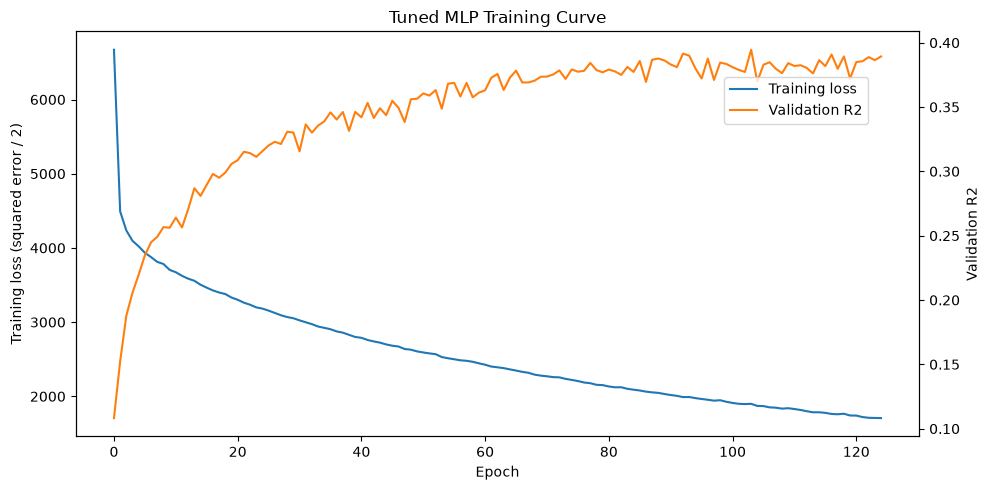

In [11]:
# Training loss & early stopping validation score of the tuned model
mlp = MLP_model.named_steps["model"]
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(mlp.loss_curve_, label="Training loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Training loss (squared error / 2)")
ax2 = ax1.twinx()
ax2.plot(mlp.validation_scores_, color="tab:orange", label="Validation R2")
ax2.set_ylabel("Validation R2")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.85))
plt.title("Tuned MLP Training Curve")
plt.tight_layout()
plt.savefig("plots/mlp_loss_curve")
plt.show()

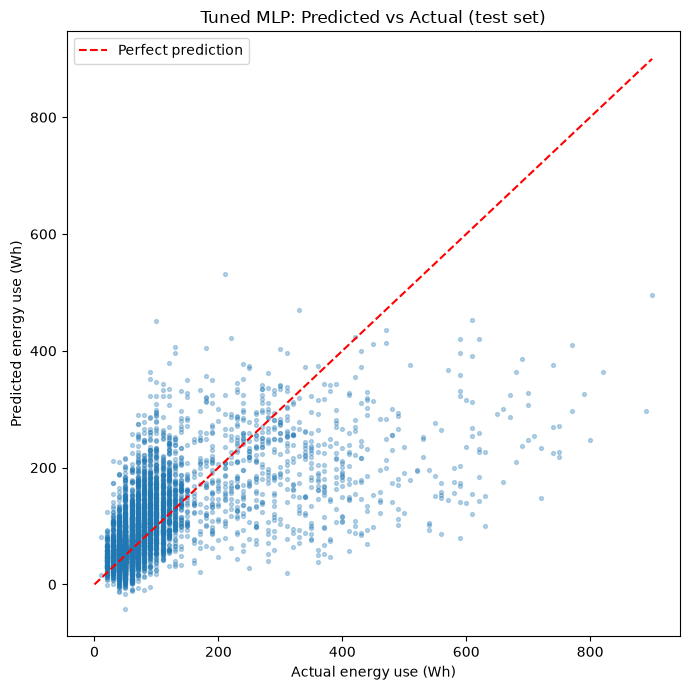

In [12]:
# Predicted vs actual on the test set
y_pred = MLP_model.predict(X_test)
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, s=8, alpha=0.3)
limit = max(y_test.max(), y_pred.max())
plt.plot([0, limit], [0, limit], color="red", linestyle="--", label="Perfect prediction")
plt.xlabel("Actual energy use (Wh)")
plt.ylabel("Predicted energy use (Wh)")
plt.title("Tuned MLP: Predicted vs Actual (test set)")
plt.legend()
plt.tight_layout()
plt.savefig("plots/mlp_predicted_vs_actual")
plt.show()

## Comparison
KNN and Bagging (MLP base estimator) scores are taken from `knn.ipynb` and `bagging.ipynb`, which use the same split.

,model,MAE,MSE,RMSE
0,Training-mean baseline,60.479910,10302.633555,101.501889
1,Default MLP,48.851797,7546.562692,86.870954
2,Tuned MLP,45.317142,6331.241236,79.569097
3,KNN Regressor,35.075658,5518.745043,74.288256
4,Bagging (MLP base),48.394097,7579.672418,87.061314


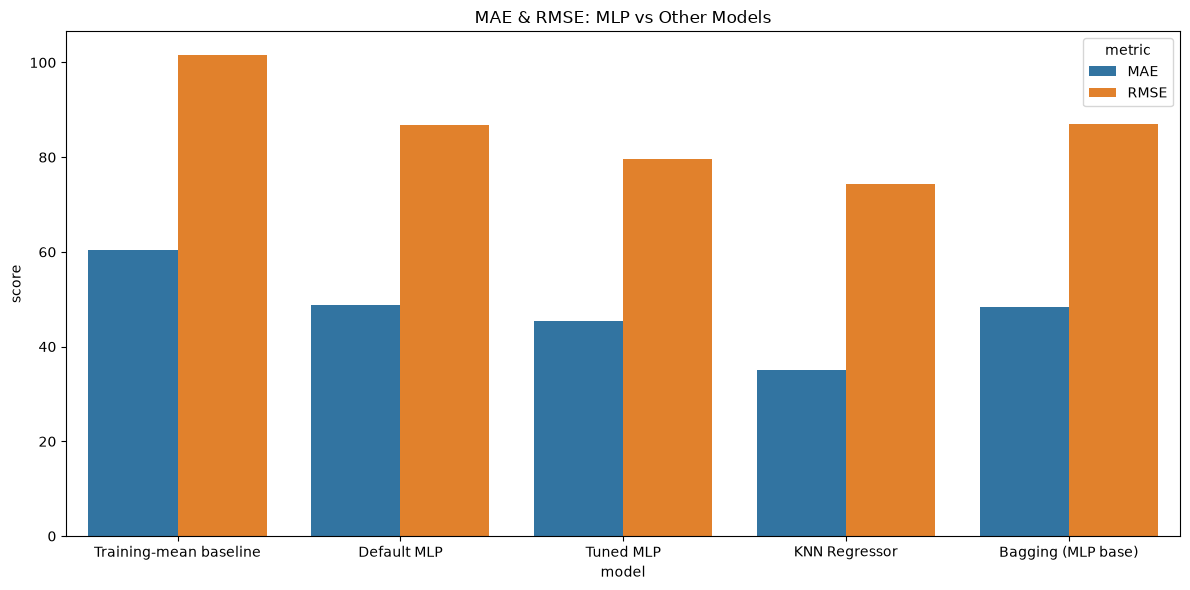

In [13]:
comparison = pd.DataFrame([
    baseline_scores,
    default_scores,
    tuned_scores,
    {"model": "KNN Regressor", "MAE": 35.07565836019646, "MSE": 5518.745043419068, "RMSE": 74.28825643006482},
    {"model": "Bagging (MLP base)", "MAE": 48.39409740597133, "MSE": 7579.6724178089, "RMSE": 87.0613141286582},
])
comparison["model"] = comparison["model"].str.replace(" (test)", "", regex=False)
display(comparison[["model", "MAE", "MSE", "RMSE"]])

plot_df = comparison.melt(id_vars="model", value_vars=["MAE", "RMSE"], var_name="metric", value_name="score")
plt.figure(figsize=(12, 6))
sns.barplot(data=plot_df, x="model", y="score", hue="metric")
plt.title("MAE & RMSE: MLP vs Other Models")
plt.tight_layout()
plt.savefig("plots/mlp_results_plot")
plt.show()

In [14]:
# Overfitting check: train vs test error
overfit = pd.DataFrame([
    {"model": "Default MLP", "train MAE": default_train_scores["MAE"], "test MAE": default_scores["MAE"],
     "train RMSE": default_train_scores["RMSE"], "test RMSE": default_scores["RMSE"]},
    {"model": "Tuned MLP", "train MAE": tuned_train_scores["MAE"], "test MAE": tuned_scores["MAE"],
     "train RMSE": tuned_train_scores["RMSE"], "test RMSE": tuned_scores["RMSE"]},
])
overfit

,model,train MAE,test MAE,train RMSE,test RMSE
0,Default MLP,47.755498,48.851797,85.502365,86.870954
1,Tuned MLP,35.650127,45.317142,62.133380,79.569097


## Results
| Model | MAE (Wh) | MSE (Wh²) | RMSE (Wh) |
|---|---|---|---|
| Training-mean baseline | 60.48 | 10,302.63 | 101.50 |
| Default MLP | 48.85 | 7,546.56 | 86.87 |
| Tuned MLP | 45.32 | 6,331.24 | 79.57 |
| KNN Regressor | 35.08 | 5,518.75 | 74.29 |
| Bagging (MLP base) | 48.39 | 7,579.67 | 87.06 |

The best parameters were one hidden layer of 200 neurons, tanh activation, `alpha` = 0.01, learning rate 0.005, and batch size 64. Tuning lowered test MAE by 3.5 Wh and RMSE by 7.3 Wh compared to the default MLP, and the tuned MLP also beat the Bagging Regressor with an MLP base estimator. KNN still has the lowest error of these models.

The default MLP has almost the same train and test error, so it is underfitting (it also hit the 200 iteration limit before converging). The tuned MLP has a larger gap between train MAE (35.65) and test MAE (45.32), meaning it is starting to overfit, but its test error is still lower. The R² of about 0.39 shows that a large part of the variation in appliance energy use is not explained by the temperature, humidity, weather, and date features.